In [86]:
# imports
# reading data from OPS and DustTrak during the YSF June 2025 iFireNet experiment

# imports 
import os
import datetime as dt
import scipy.io
import numpy as np  
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch
import seaborn as sns

import re

# Establish the project directory
try:
    proj_dir = os.path.dirname(os.path.abspath(__file__))  # get the project directory
except NameError:
    proj_dir = os.getcwd()  # fallback if __file__ is not defined




In [177]:
# set a few parameters for the plot making
plt.rcParams['font.size'] = 14
plt.rcParams['font.family'] = 'Arial'

plt.rcParams['figure.dpi'] = 300
plt.rcParams['figure.figsize'] = (12, 6)

plt.rcParams['lines.linewidth'] = 1.5

plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.5
plt.rcParams['legend.frameon'] = True
plt.rcParams['legend.framealpha'] = 0.8
plt.rcParams['legend.loc'] = 'best'
plt.rcParams['legend.fontsize'] = 16
plt.rcParams['axes.titlesize'] = 26
plt.rcParams['axes.labelsize'] = 20
plt.rcParams['xtick.labelsize'] = 22
plt.rcParams['ytick.labelsize'] = 22
plt.rcParams['figure.autolayout'] = True  # adjust layout to prevent overlap

# plt.rcParams.update({
#     'axes.titlesize': 18,  # Title font size
#     'axes.labelsize': 14,  # X and Y axis label font size
#     'xtick.labelsize': 22,  # X-axis tick numbers
#     'ytick.labelsize': 22,  # Y-axis tick numbers
#     'legend.fontsize': 12,  # Legend text size
# })


In [88]:
# setting up a few event times for the experiment. reference the field_notes.md file. 
ignition = pd.Timestamp('2025-06-10 09:28:00')
burn_complete = pd.Timestamp('2025-06-10 10:27:00')

site1_fullsmoke = pd.Timestamp('2025-06-10 09:55:00')
site1_airclear = pd.Timestamp('2025-06-10 10:00:00')


# Analysis for Particulate Matter Number Concentration on June 10th. 

In [89]:
# reading data from OPS and DustTrak
def read_ops(csv_file_path):
    """ Reads the OPS data from a CSV file and returns a DataFrame with metadata.
    Returns (Tuple):
        metadata_dict (dict): Dictionary containing metadata from the OPS file.
        df (pd.DataFrame): DataFrame containing the OPS data.
    """
    # read the csv file
    with open(csv_file_path, 'r') as f:
        content = f.readlines()

    metadata = content[0:37]  # first 37 lines are metadata
    # convert metadata to a dictionary
    metadata_dict = {}
    bin_cut_points = {}
    for line in metadata:
        key, value = line.strip().split(',', 1)
        match = re.match(r'Bin (\d+) Cut Point \(um\)', key)
        if match:
            bin_number = int(match.group(1))
            bin_cut_points[bin_number] = float(value)
        else:
            metadata_dict[key.strip()] = value.strip()
    metadata_dict['Bin Cut Points'] = bin_cut_points

    df = pd.read_csv(csv_file_path, skiprows=37) 
    # convert columns to appropriate data types
    start_datetime = dt.datetime.strptime(
            f"{metadata_dict['Test Start Date']} {metadata_dict['Test Start Time']}"
            , "%Y/%m/%d %H:%M:%S"
        )
    print(f"Start datetime: {start_datetime}")
    df['datetime'] = start_datetime + pd.to_timedelta(df['Elapsed Time [s]'], unit='s')

    return [metadata_dict, df]


ops_data_file = r"..\data\00_raw\OPS\2025_06_10-07_55_53-TEST_001.csv" #'..\data\OPS\2025_06_10-07_55_53-TEST_001.csv' 

ops_meta, ops_df = read_ops(ops_data_file)

# trim first 10 minutes of day 2 and day 3 data
ops_df = ops_df[ops_df['datetime'] >= ops_df['datetime'].min() + pd.Timedelta(minutes=10)]

# sort and set datetime index
ops_df = ops_df.sort_values('datetime').set_index('datetime') # only need to run this once.

print(ops_meta)
ops_df

Start datetime: 2025-06-10 07:55:53
{'Instrument Name': 'Optical Particle Sizer', 'Model Number': '3330', 'Serial Number': '3330142801', 'Firmware Version': '1.4', 'Calibration Date': '2018/07/03', 'Protocol Name_Number': 'TEST_001', 'Test Start Time': '07:55:53', 'Test Start Date': '2025/06/10', 'Test Length [D:H:M:S]': '0:5:43:31', 'Sample Interval [H:M:S]': '0:0:1', 'Number Channels Enabled': '16', 'Alarm': '0.000 #/cm3', 'Density': '1.000', 'Refractive Index': '0.000-0.000j', 'Size Correction Factor': '0.000', 'FlowCal': '1.000', 'DeadTime Correction Factor': '1.000', 'Errors': 'Coincidence Error', 'Number of Samples': '20611', '': '', 'Bin Cut Points': {1: 0.3, 2: 0.374, 3: 0.465, 4: 0.579, 5: 0.721, 6: 0.897, 7: 1.117, 8: 1.391, 9: 1.732, 10: 2.156, 11: 2.685, 12: 3.343, 13: 4.162, 14: 5.182, 15: 6.451, 16: 8.031, 17: 10.0}}


,Elapsed Time [s],Bin 1,Bin 2,Bin 3,Bin 4,Bin 5,Bin 6,Bin 7,Bin 8,Bin 9,...,Bin 15,Bin 16,Bin 17,Deadtime (s),Temperature (C),Humidity (%),Ambient Pressure (kPa),Alarms,Errors,Unnamed: 24
datetime,,,,,,,,,,,,,,,,,,,,,
2025-06-10 08:05:54,601,781,203,25,4,5,5,2,2,0,...,0,0,0,0.005753,29.579,0.0,96.920,NaN,NaN,NaN
2025-06-10 08:05:55,602,731,211,34,10,2,6,1,1,1,...,0,0,0,0.005766,29.579,0.0,96.920,NaN,NaN,NaN
2025-06-10 08:05:56,603,797,183,39,7,7,6,1,1,3,...,0,0,0,0.005662,29.579,0.0,96.920,NaN,NaN,NaN
2025-06-10 08:05:57,604,791,214,32,12,2,3,4,0,2,...,0,0,0,0.005999,29.579,0.0,96.920,NaN,NaN,NaN
2025-06-10 08:05:58,605,781,206,35,5,3,1,0,2,3,...,0,0,0,0.005752,29.579,0.0,96.920,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-06-10 13:39:20,20607,270,89,18,8,1,3,3,3,1,...,0,0,0,0.002126,54.559,0.0,96.857,NaN,NaN,NaN
2025-06-10 13:39:21,20608,316,89,13,7,6,5,2,3,1,...,0,0,0,0.002478,54.559,0.0,96.857,NaN,NaN,NaN
2025-06-10 13:39:22,20609,280,93,16,7,5,4,0,4,1,...,1,0,0,0.002285,54.559,0.0,96.857,NaN,NaN,NaN


In [90]:
# print the bin cut points
for b in ops_meta['Bin Cut Points'].keys():
    print(f"Bin {b} Cut Point (um): {ops_meta['Bin Cut Points'][b]}")

Bin 1 Cut Point (um): 0.3
Bin 2 Cut Point (um): 0.374
Bin 3 Cut Point (um): 0.465
Bin 4 Cut Point (um): 0.579
Bin 5 Cut Point (um): 0.721
Bin 6 Cut Point (um): 0.897
Bin 7 Cut Point (um): 1.117
Bin 8 Cut Point (um): 1.391
Bin 9 Cut Point (um): 1.732
Bin 10 Cut Point (um): 2.156
Bin 11 Cut Point (um): 2.685
Bin 12 Cut Point (um): 3.343
Bin 13 Cut Point (um): 4.162
Bin 14 Cut Point (um): 5.182
Bin 15 Cut Point (um): 6.451
Bin 16 Cut Point (um): 8.031
Bin 17 Cut Point (um): 10.0


In [91]:
# add a column for the phase of the experiment
def assign_phase(row):
    if row.name < ignition:
        return 'Pre-burn'
    elif ignition <= row.name <= burn_complete:
        return 'Burn'
    else:
        return 'Post-burn'
ops_df['Phase'] = ops_df.apply(assign_phase, axis=1)


In [92]:
ops_df

,Elapsed Time [s],Bin 1,Bin 2,Bin 3,Bin 4,Bin 5,Bin 6,Bin 7,Bin 8,Bin 9,...,Bin 16,Bin 17,Deadtime (s),Temperature (C),Humidity (%),Ambient Pressure (kPa),Alarms,Errors,Unnamed: 24,Phase
datetime,,,,,,,,,,,,,,,,,,,,,
2025-06-10 08:05:54,601,781,203,25,4,5,5,2,2,0,...,0,0,0.005753,29.579,0.0,96.920,NaN,NaN,NaN,Pre-burn
2025-06-10 08:05:55,602,731,211,34,10,2,6,1,1,1,...,0,0,0.005766,29.579,0.0,96.920,NaN,NaN,NaN,Pre-burn
2025-06-10 08:05:56,603,797,183,39,7,7,6,1,1,3,...,0,0,0.005662,29.579,0.0,96.920,NaN,NaN,NaN,Pre-burn
2025-06-10 08:05:57,604,791,214,32,12,2,3,4,0,2,...,0,0,0.005999,29.579,0.0,96.920,NaN,NaN,NaN,Pre-burn
2025-06-10 08:05:58,605,781,206,35,5,3,1,0,2,3,...,0,0,0.005752,29.579,0.0,96.920,NaN,NaN,NaN,Pre-burn
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-06-10 13:39:20,20607,270,89,18,8,1,3,3,3,1,...,0,0,0.002126,54.559,0.0,96.857,NaN,NaN,NaN,Post-burn
2025-06-10 13:39:21,20608,316,89,13,7,6,5,2,3,1,...,0,0,0.002478,54.559,0.0,96.857,NaN,NaN,NaN,Post-burn
2025-06-10 13:39:22,20609,280,93,16,7,5,4,0,4,1,...,0,0,0.002285,54.559,0.0,96.857,NaN,NaN,NaN,Post-burn


In [93]:
# combine the bins so we have pm1, pm2.5, and pm10

# find OPS bin columns in the dataframe
bin_cols = [c for c in ops_df.columns if re.match(r'Bin\s*\d+', c, re.IGNORECASE)]
bin_map = {int(re.search(r'\d+', c).group()): c for c in bin_cols}

pm_groups = {'PM1': [], 'PM2.5': [], 'PM10': []}

for bin_num, cut_point in ops_meta['Bin Cut Points'].items():
    if bin_num not in bin_map:
        continue
    col = bin_map[bin_num]
    if cut_point <= 1.0:
        pm_groups['PM1'].append(col)
    if cut_point > 1.0 and cut_point <= 2.5:
        pm_groups['PM2.5'].append(col)
    if cut_point > 2.5 and cut_point <= 10.0:
        pm_groups['PM10'].append(col)

for pm_name, cols in pm_groups.items():
    ops_df[pm_name] = ops_df[cols].sum(axis=1)

print("PM1 bins:", pm_groups['PM1'])
print("PM2.5 bins:", pm_groups['PM2.5'])
print("PM10 bins:", pm_groups['PM10'])

PM1 bins: ['Bin 1', 'Bin 2', 'Bin 3', 'Bin 4', 'Bin 5', 'Bin 6']
PM2.5 bins: ['Bin 7', 'Bin 8', 'Bin 9', 'Bin 10']
PM10 bins: ['Bin 11', 'Bin 12', 'Bin 13', 'Bin 14', 'Bin 15', 'Bin 16', 'Bin 17']


In [94]:
# smoothing the data out... rolling smoothing min or s for seconds (tested with 30s, 1min, and 5min - 30s seems to work best for this data)
ops_df['PM1_smooth'] = ops_df['PM1'].rolling('30s', center=True).mean()
ops_df['PM25_smooth'] = ops_df['PM2.5'].rolling('30s', center=True).mean()
ops_df['PM10_smooth'] = ops_df['PM10'].rolling('30s', center=True).mean()


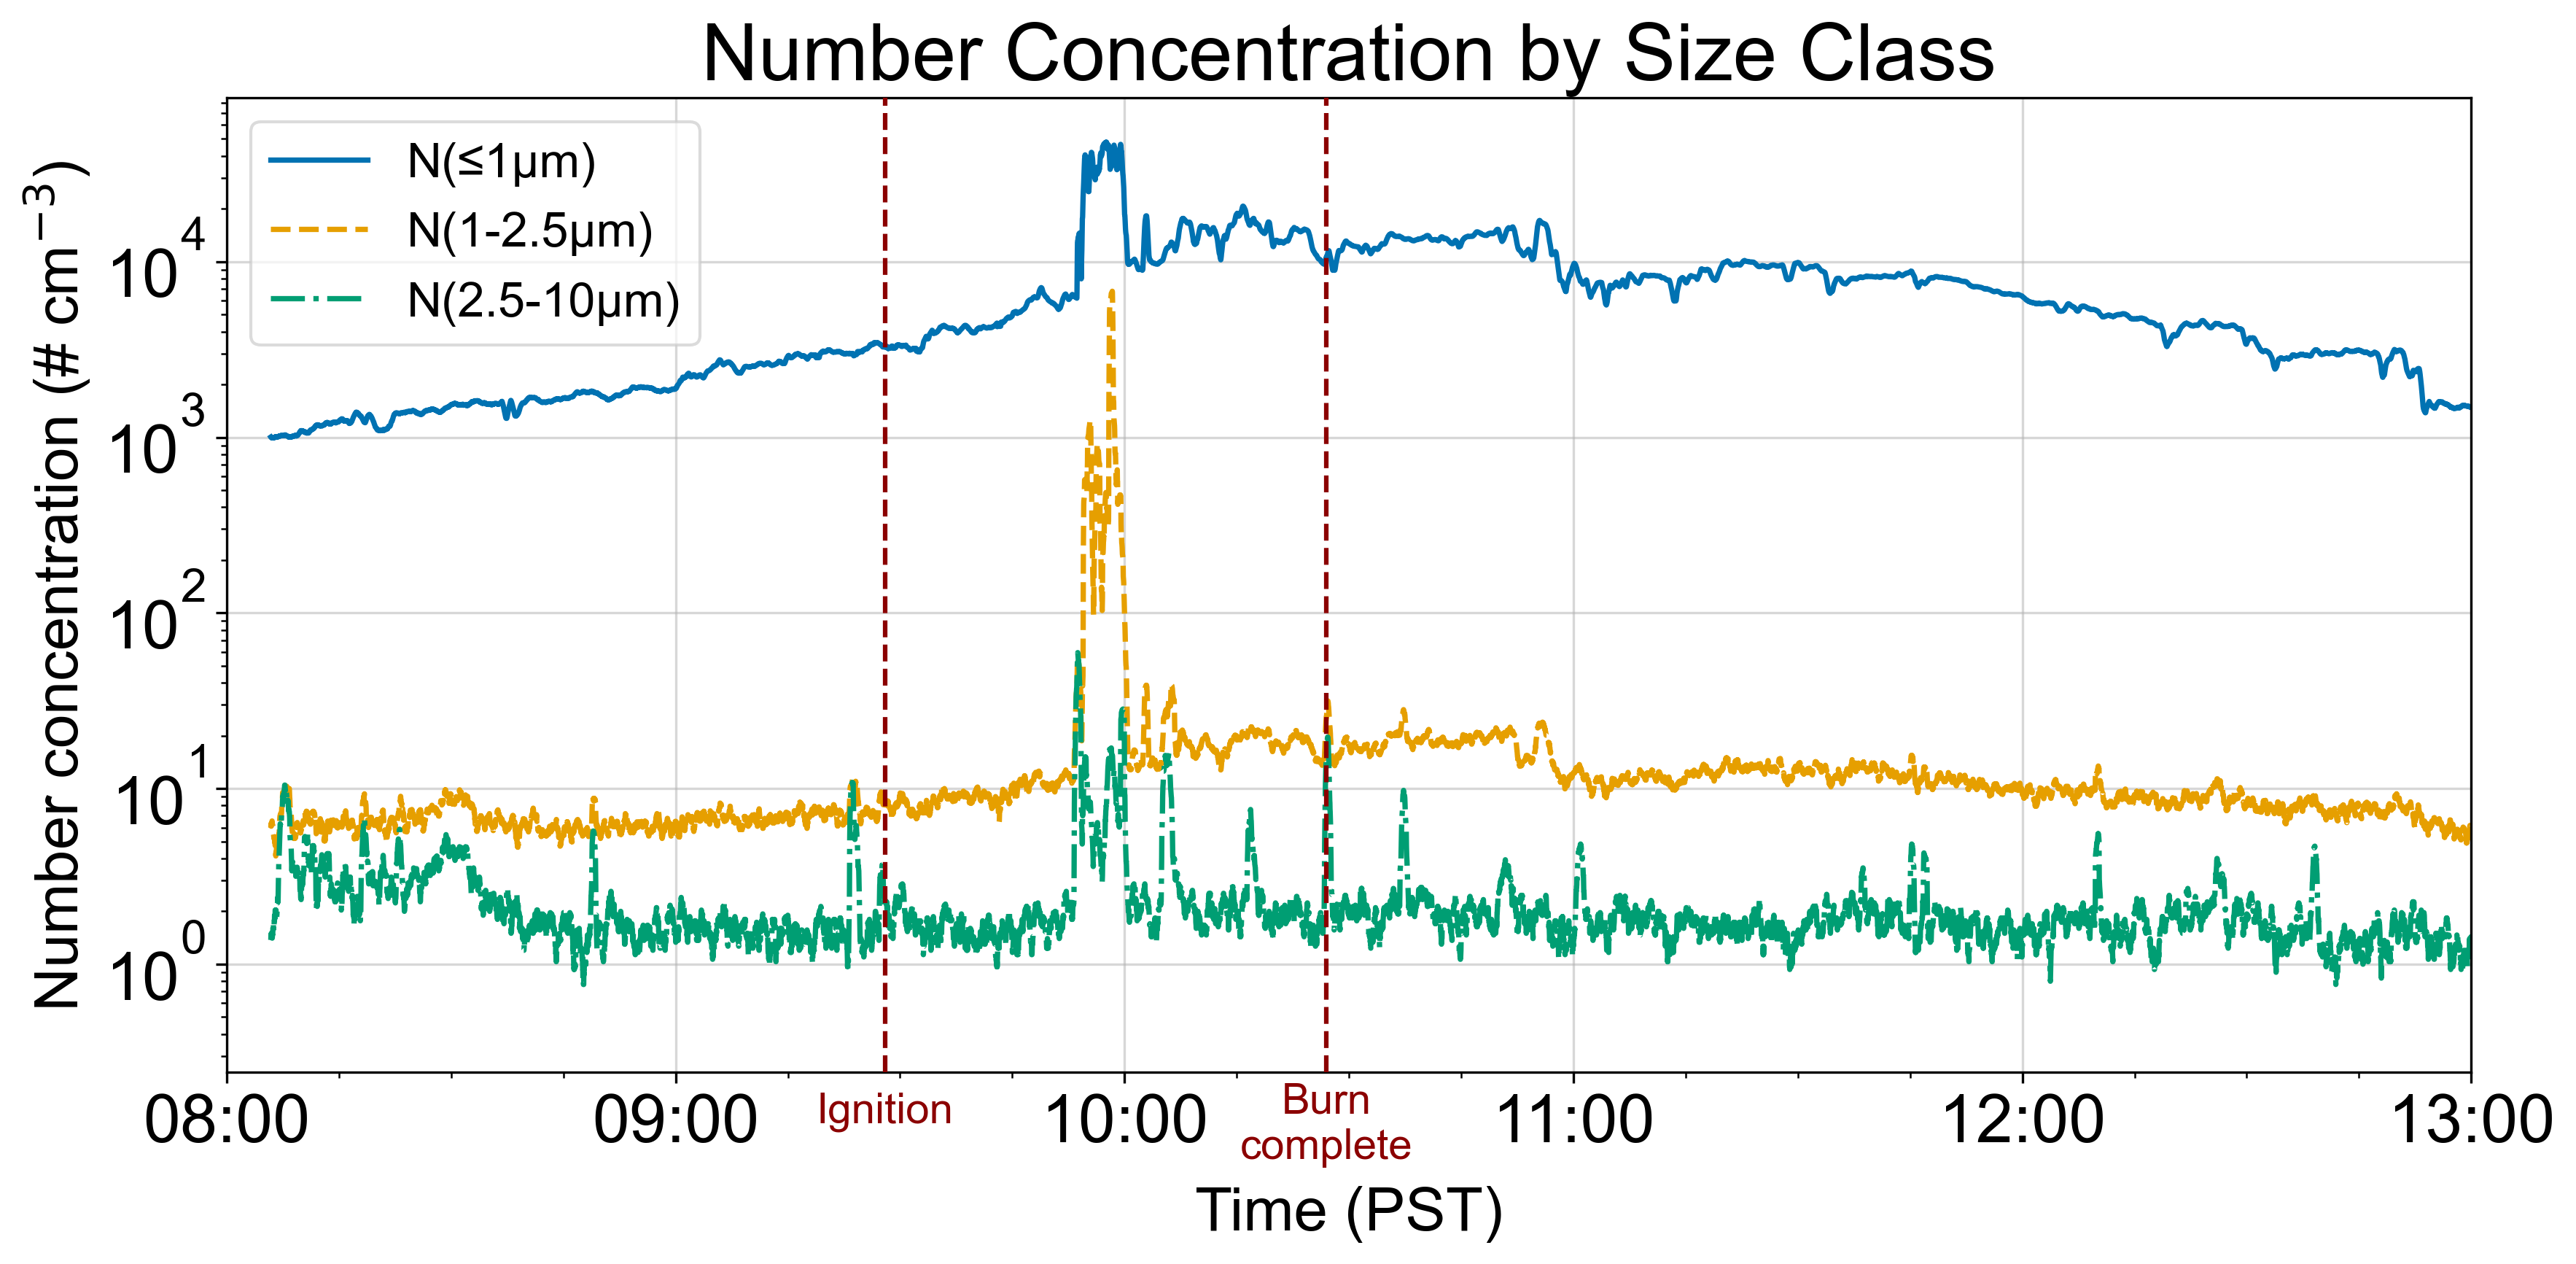

In [188]:
# I think the log scale is the best way to show the data, but I can also do a linear scale if needed. I will start with log and then we can decide if we want to change it.

plt.figure(figsize=(12, 6))

plt.plot(ops_df.index, ops_df['PM1_smooth'], label='N(≤1µm)', color='#0072B2',linestyle='-', linewidth=1.75)  #'#0072B2'#4C78A8)
plt.plot(ops_df.index, ops_df['PM25_smooth'], label='N(1-2.5µm)', color='#E69F00',linestyle='--', linewidth=1.75)
plt.plot(ops_df.index, ops_df['PM10_smooth'], label='N(2.5-10µm)', color='#009E73',linestyle='-.', linewidth=1.75)

plt.title('Number Concentration by Size Class')
plt.xlabel('Time (PST)', labelpad=10)
plt.ylabel('Number concentration (# cm$^{-3}$)')

# format x-axis
time_formatter = mdates.DateFormatter("%H:%M")
plt.gca().xaxis.set_major_formatter(time_formatter)
plt.gca().xaxis.set_minor_locator(mdates.MinuteLocator(byminute=[0, 15, 30, 45]))
# plt.xticks(rotation=45)
plt.xlim(pd.Timestamp('2025-06-10 08:00:00'), pd.Timestamp('2025-06-10 13:00:00'))
ax = plt.gca()

plt.axvline(x=ignition, color='darkred', linestyle='--', linewidth=1.5, zorder=10)
plt.axvline(x=burn_complete, color='darkred', linestyle='--', linewidth=1.5, zorder=10)

ax.text(
    ignition, -0.02, 'Ignition',
    transform=ax.get_xaxis_transform(),
    # rotation=45, 
    va='top', ha='center',
    color='darkred', clip_on=False
)

ax.text(
    burn_complete, -0.01, 'Burn\ncomplete',
    transform=ax.get_xaxis_transform(),
    # rotation=45, 
    va='top', ha='center',
    color='darkred', clip_on=False
)

plt.legend(framealpha=0.7, loc='upper left')

plt.yscale('log')
plt.tight_layout()

plt.show()


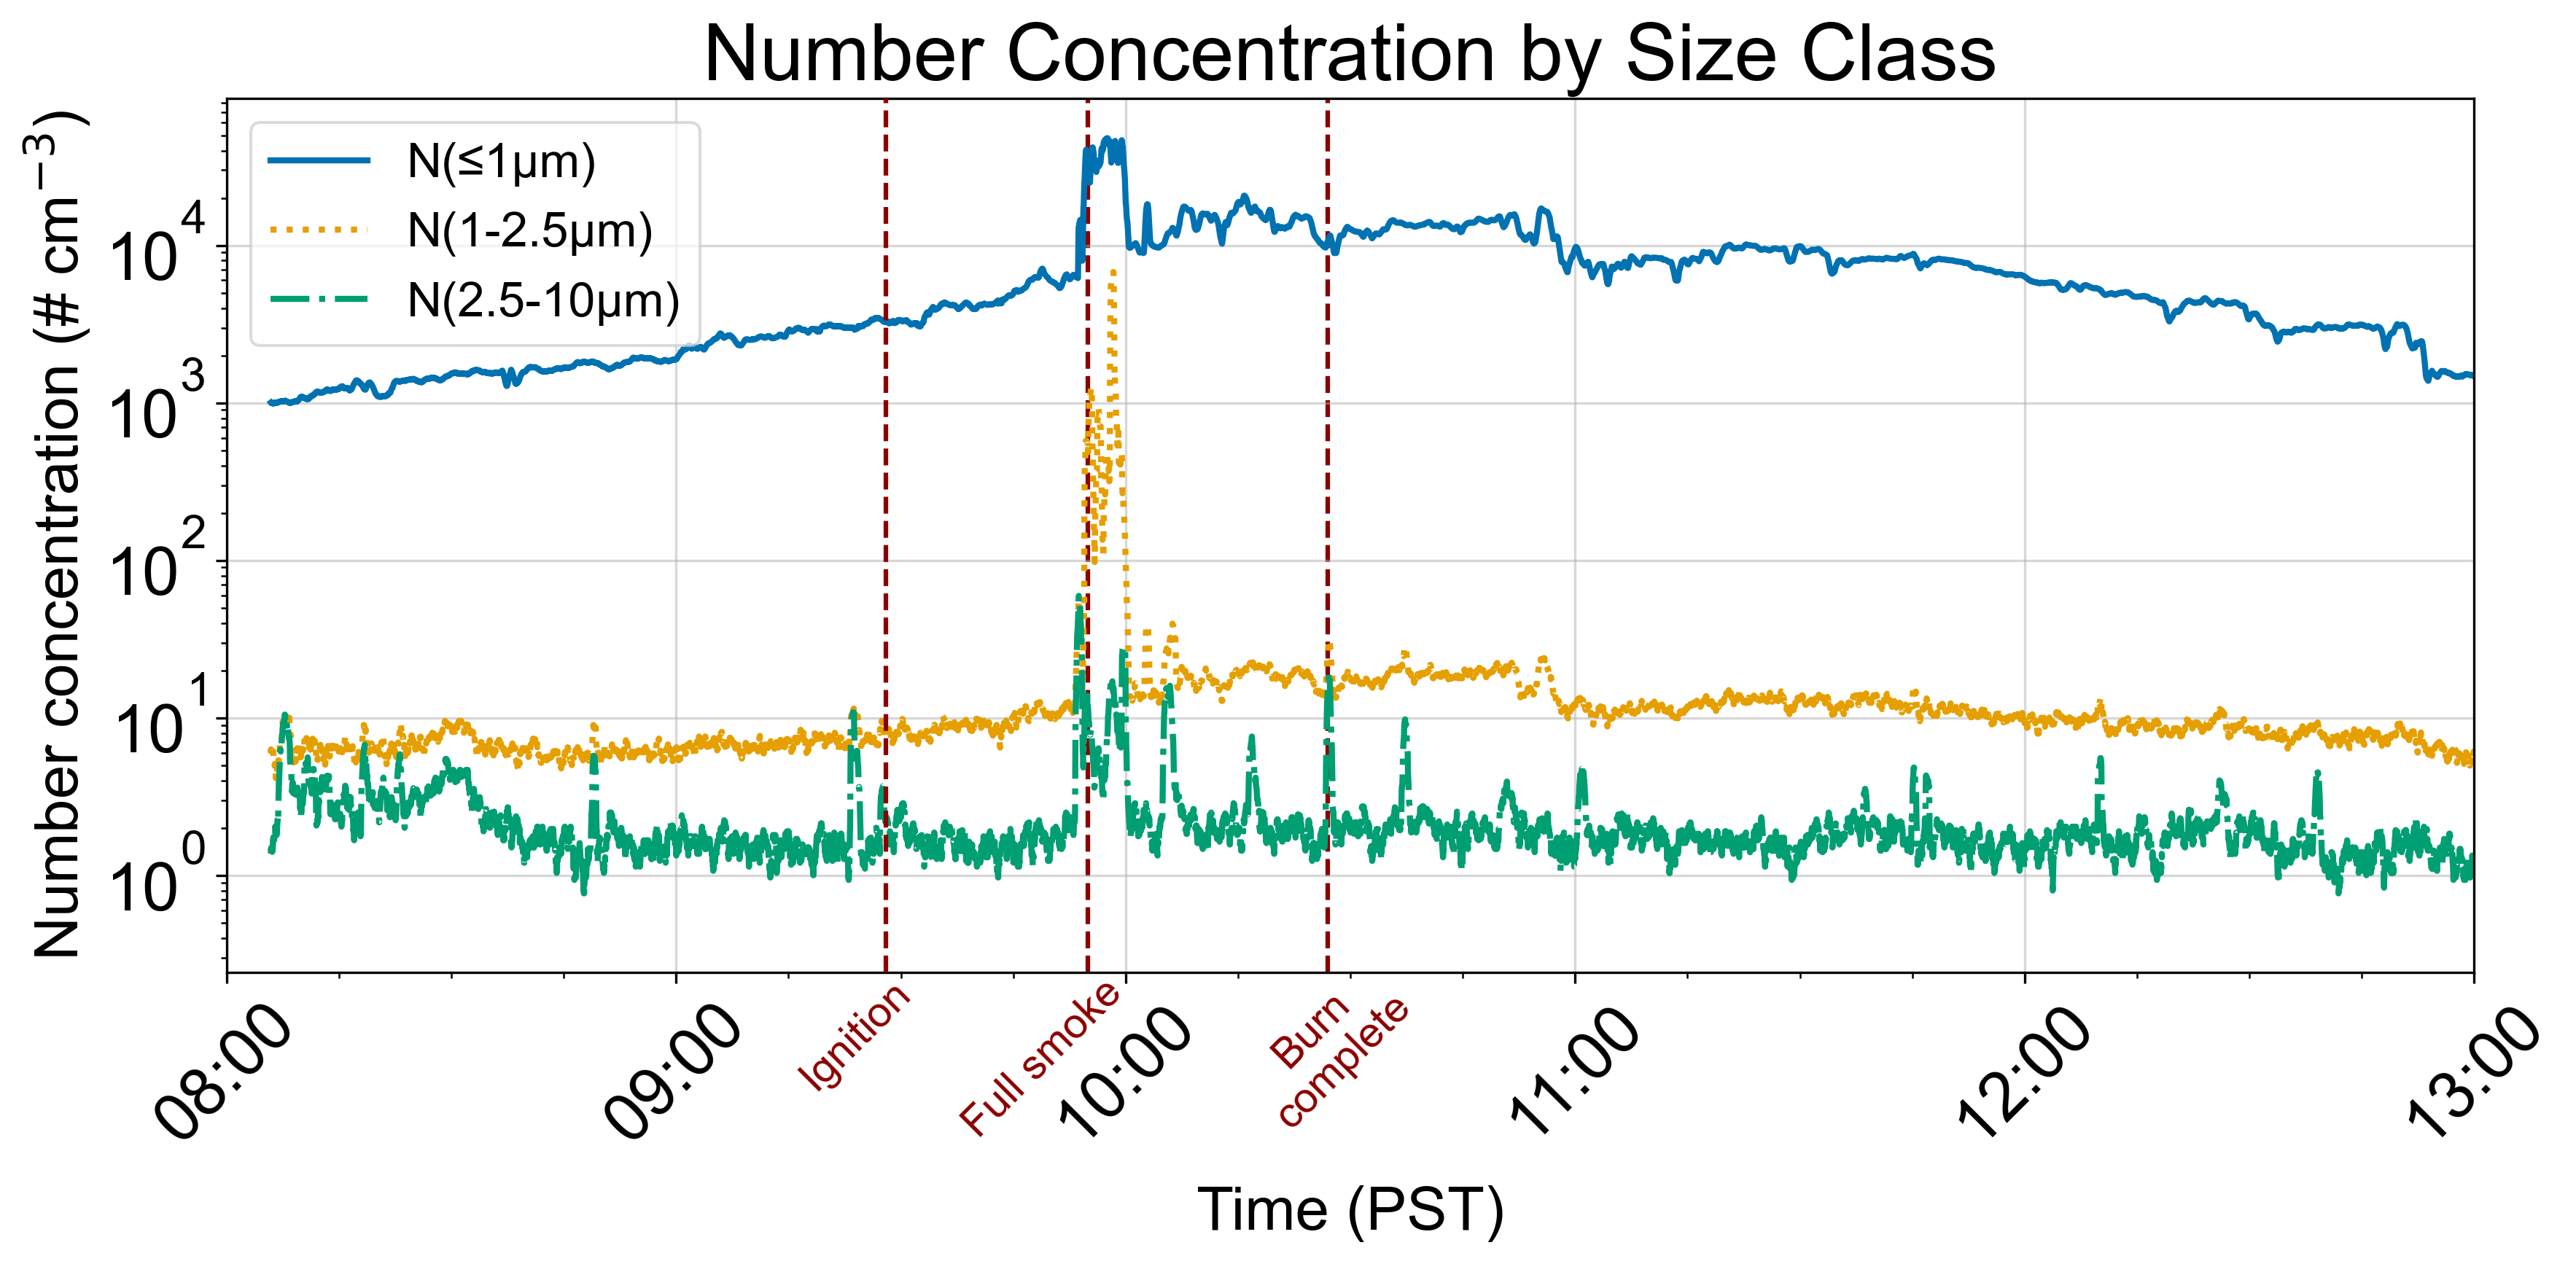

In [178]:
# I want another version of this plot with more vertical lines for other events that happened during the experiment.


plt.figure(figsize=(12, 6))

plt.plot(ops_df.index, ops_df['PM1_smooth'], label='N(≤1µm)', color='#0072B2',linestyle='-', linewidth=2)  #'#0072B2'#4C78A8)
plt.plot(ops_df.index, ops_df['PM25_smooth'], label='N(1-2.5µm)', color='#E69F00',linestyle=':', linewidth=2)
plt.plot(ops_df.index, ops_df['PM10_smooth'], label='N(2.5-10µm)', color='#009E73',linestyle='-.', linewidth=2)

plt.title('Number Concentration by Size Class')
plt.xlabel('Time (PST)', labelpad=10)
plt.ylabel('Number concentration (# cm$^{-3}$)')

# format x-axis
time_formatter = mdates.DateFormatter("%H:%M")
plt.gca().xaxis.set_major_formatter(time_formatter)
plt.gca().xaxis.set_minor_locator(mdates.MinuteLocator(byminute=[0, 15, 30, 45]))
plt.xticks(rotation=45)
plt.xlim(pd.Timestamp('2025-06-10 08:00:00'), pd.Timestamp('2025-06-10 13:00:00'))
ax = plt.gca()


plt.legend(framealpha=0.7, loc='upper left')


plt.axvline(x=ignition, color='darkred', linestyle='--', linewidth=1.5, zorder=10)
plt.axvline(x=burn_complete, color='darkred', linestyle='--', linewidth=1.5, zorder=1)

# plt.axvspan(xmin=site1_fullsmoke, xmax=site1_airclear, color='darkred', alpha=0.2, zorder=1)
plt.axvline(x=site1_fullsmoke, color='darkred', linestyle='--', linewidth=1.5, zorder=1)



ax.text(
    ignition- pd.Timedelta(minutes=4), -0.001, 'Ignition',
    transform=ax.get_xaxis_transform(), rotation=45, 
    va='top', ha='center',
    color='darkred', clip_on=False
)

ax.text(
    burn_complete, 0.02, 'Burn\ncomplete',
    transform=ax.get_xaxis_transform(), rotation=45, 
    va='top', ha='center',
    color='darkred', clip_on=False
)

ax.text(
    site1_fullsmoke - pd.Timedelta(minutes=6), 0.0, 'Full smoke',
    transform=ax.get_xaxis_transform(), rotation=45, 
    va='top', ha='center',
    color='darkred', clip_on=False
)



plt.yscale('log')

plt.show()


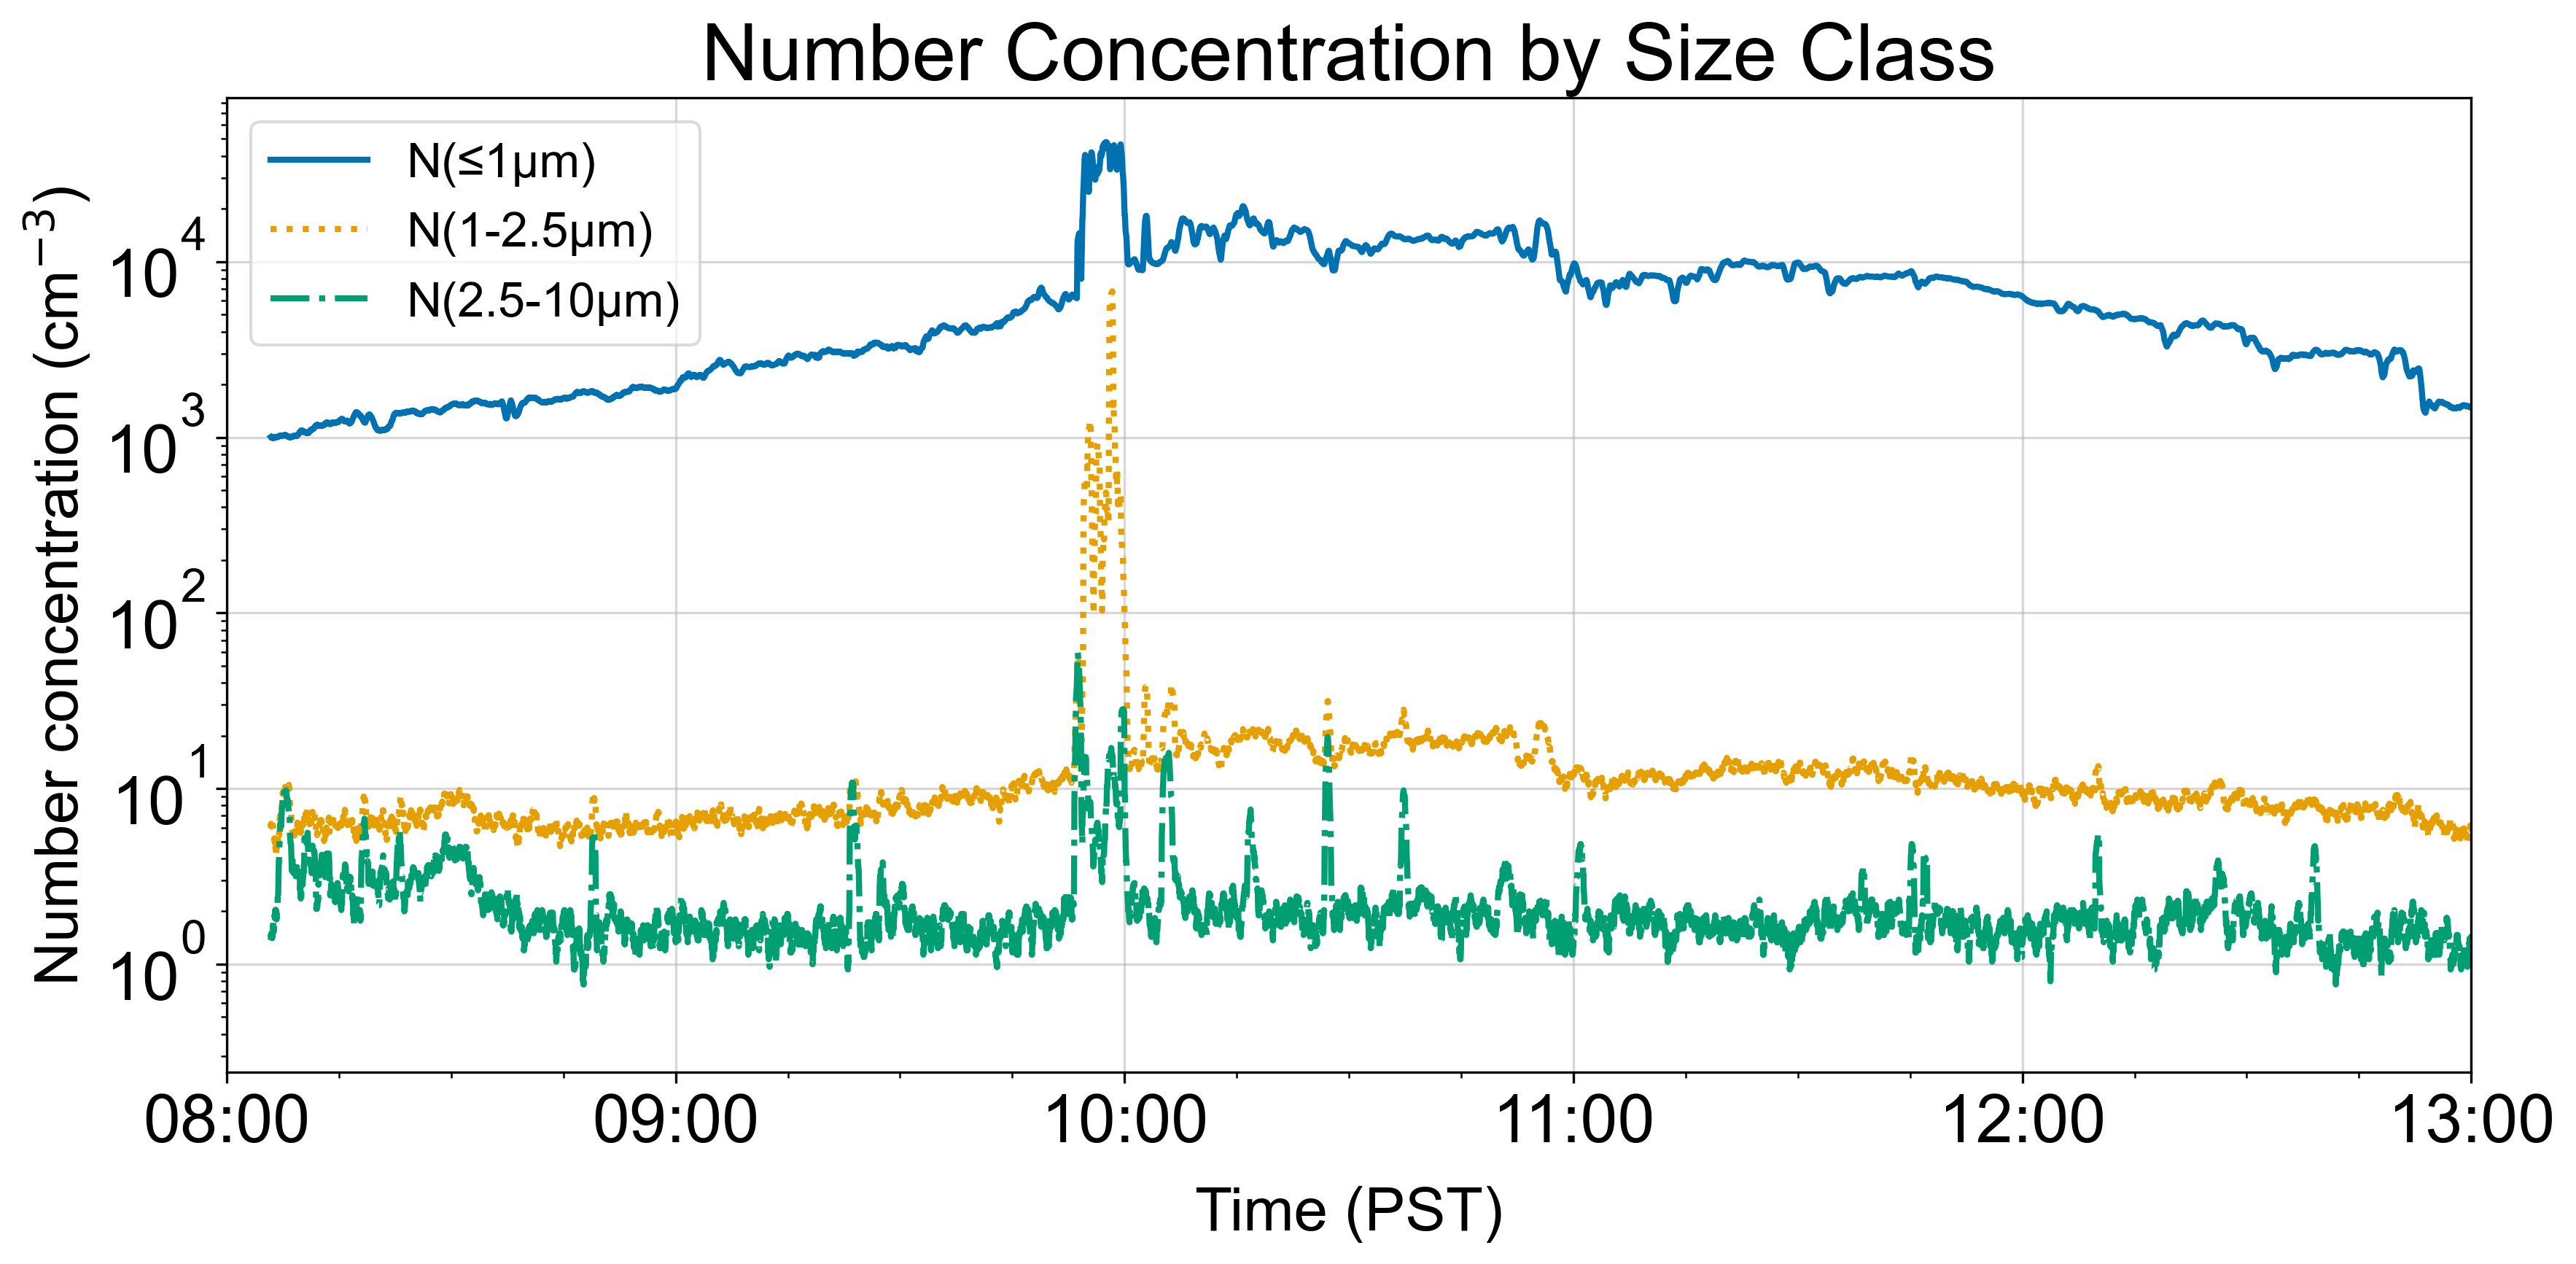

In [181]:
# I want another version of this plot with more vertical lines for other events that happened during the experiment.


plt.figure(figsize=(12, 6))

plt.plot(ops_df.index, ops_df['PM1_smooth'], label='N(≤1µm)', color='#0072B2',linestyle='-', linewidth=2)  #'#0072B2'#4C78A8)
plt.plot(ops_df.index, ops_df['PM25_smooth'], label='N(1-2.5µm)', color='#E69F00',linestyle=':', linewidth=2)
plt.plot(ops_df.index, ops_df['PM10_smooth'], label='N(2.5-10µm)', color='#009E73',linestyle='-.', linewidth=2)

plt.title('Number Concentration by Size Class')
plt.xlabel('Time (PST)', labelpad=10)
plt.ylabel('Number concentration (cm$^{-3}$)')

# format x-axis
time_formatter = mdates.DateFormatter("%H:%M")
plt.gca().xaxis.set_major_formatter(time_formatter)
plt.gca().xaxis.set_minor_locator(mdates.MinuteLocator(byminute=[0, 15, 30, 45]))
# plt.xticks(rotation=45)
plt.xlim(pd.Timestamp('2025-06-10 08:00:00'), pd.Timestamp('2025-06-10 13:00:00'))
ax = plt.gca()

plt.legend(framealpha=0.7, loc='upper left')

# plt.axvline(x=ignition, color='darkred', linestyle='--', linewidth=1.5, zorder=10)
# plt.axvline(x=burn_complete, color='darkred', linestyle='--', linewidth=1.5, zorder=1)

# # plt.axvspan(xmin=site1_fullsmoke, xmax=site1_airclear, color='darkred', alpha=0.2, zorder=1)
# plt.axvline(x=site1_fullsmoke, color='darkred', linestyle='--', linewidth=1.5, zorder=1)

# ax.text(
#     ignition- pd.Timedelta(minutes=4), -0.001, 'Ignition',
#     backgroundcolor='white', #rotation=45,
#     transform=ax.get_xaxis_transform(), 
#     va='top', ha='center',
#     color='darkred', clip_on=False
# )

# ax.text(
#     burn_complete, 0.02, 'Burn\ncomplete',
#     transform=ax.get_xaxis_transform(),
#     backgroundcolor='white', alpha=0.7, #rotation=45, 
#     va='top', ha='center',
#     color='darkred', clip_on=False
# )

# ax.text(
#     site1_fullsmoke, 0.05, 'Full smoke',
#     transform=ax.get_xaxis_transform(), 
#     bbox=dict(facecolor="white", edgecolor="none", alpha=0.5, boxstyle="round,pad=0.4"),
#     # backgroundcolor='white', #rotation=45, 
#     va='top', ha='center',
#     color='darkred', clip_on=False
# )



plt.yscale('log')
# plt.tight_layout()

plt.show()


Working on the second figure...
here we want to compare the 30 minute mean for pre-burn, burn, and post-burn. 

In [97]:
# what if I group the bins together. 
grouped_bins = {
    '0.3-0.5 µm': ['≤ 0.3 µm', '≤ 0.374 µm', '≤ 0.465 µm'],
    '0.5-1 µm': ['≤ 0.579 µm', '≤ 0.721 µm', '≤ 0.897 µm'],
    '1.0-2.5 µm': ['≤ 1.117 µm', '≤ 1.391 µm', '≤ 1.732 µm', '≤ 2.156 µm'],
    '2.5-10 µm': ['≤ 2.685 µm', '≤ 3.343 µm', '≤ 4.162 µm', '≤ 5.182 µm', '≤ 6.451 µm', '≤ 8.031 µm', '≤ 10.0 µm']
}

# find OPS bin columns in the dataframe
bin_cols = [c for c in ops_df.columns if re.match(r'Bin\s*\d+', c, re.IGNORECASE)]
bin_map = {int(re.search(r'\d+', c).group()): c for c in bin_cols}

pm_groups = {'0.3-0.5 µm': [], '0.5-1 µm': [], '1.0-2.5 µm': [], '2.5-10 µm': []}

for bin_num, cut_point in ops_meta['Bin Cut Points'].items():
    if bin_num not in bin_map:
        continue
    col = bin_map[bin_num]
    if cut_point <= 0.5:
        pm_groups['0.3-0.5 µm'].append(col)
    if cut_point > 0.5 and cut_point <= 1.0:
        pm_groups['0.5-1 µm'].append(col)
    if cut_point > 1.0 and cut_point <= 2.5:
        pm_groups['1.0-2.5 µm'].append(col)
    if cut_point > 2.5 and cut_point <= 10.0:
        pm_groups['2.5-10 µm'].append(col)

for pm_name, cols in pm_groups.items():
    ops_df[pm_name] = ops_df[cols].sum(axis=1)

print("0.3-0.5 µm bins:", pm_groups['0.3-0.5 µm'])
print("0.5-1 µm bins:", pm_groups['0.5-1 µm'])
print("1.0-2.5 µm bins:", pm_groups['1.0-2.5 µm'])
print("2.5-10 µm bins:", pm_groups['2.5-10 µm'])

0.3-0.5 µm bins: ['Bin 1', 'Bin 2', 'Bin 3']
0.5-1 µm bins: ['Bin 4', 'Bin 5', 'Bin 6']
1.0-2.5 µm bins: ['Bin 7', 'Bin 8', 'Bin 9', 'Bin 10']
2.5-10 µm bins: ['Bin 11', 'Bin 12', 'Bin 13', 'Bin 14', 'Bin 15', 'Bin 16', 'Bin 17']


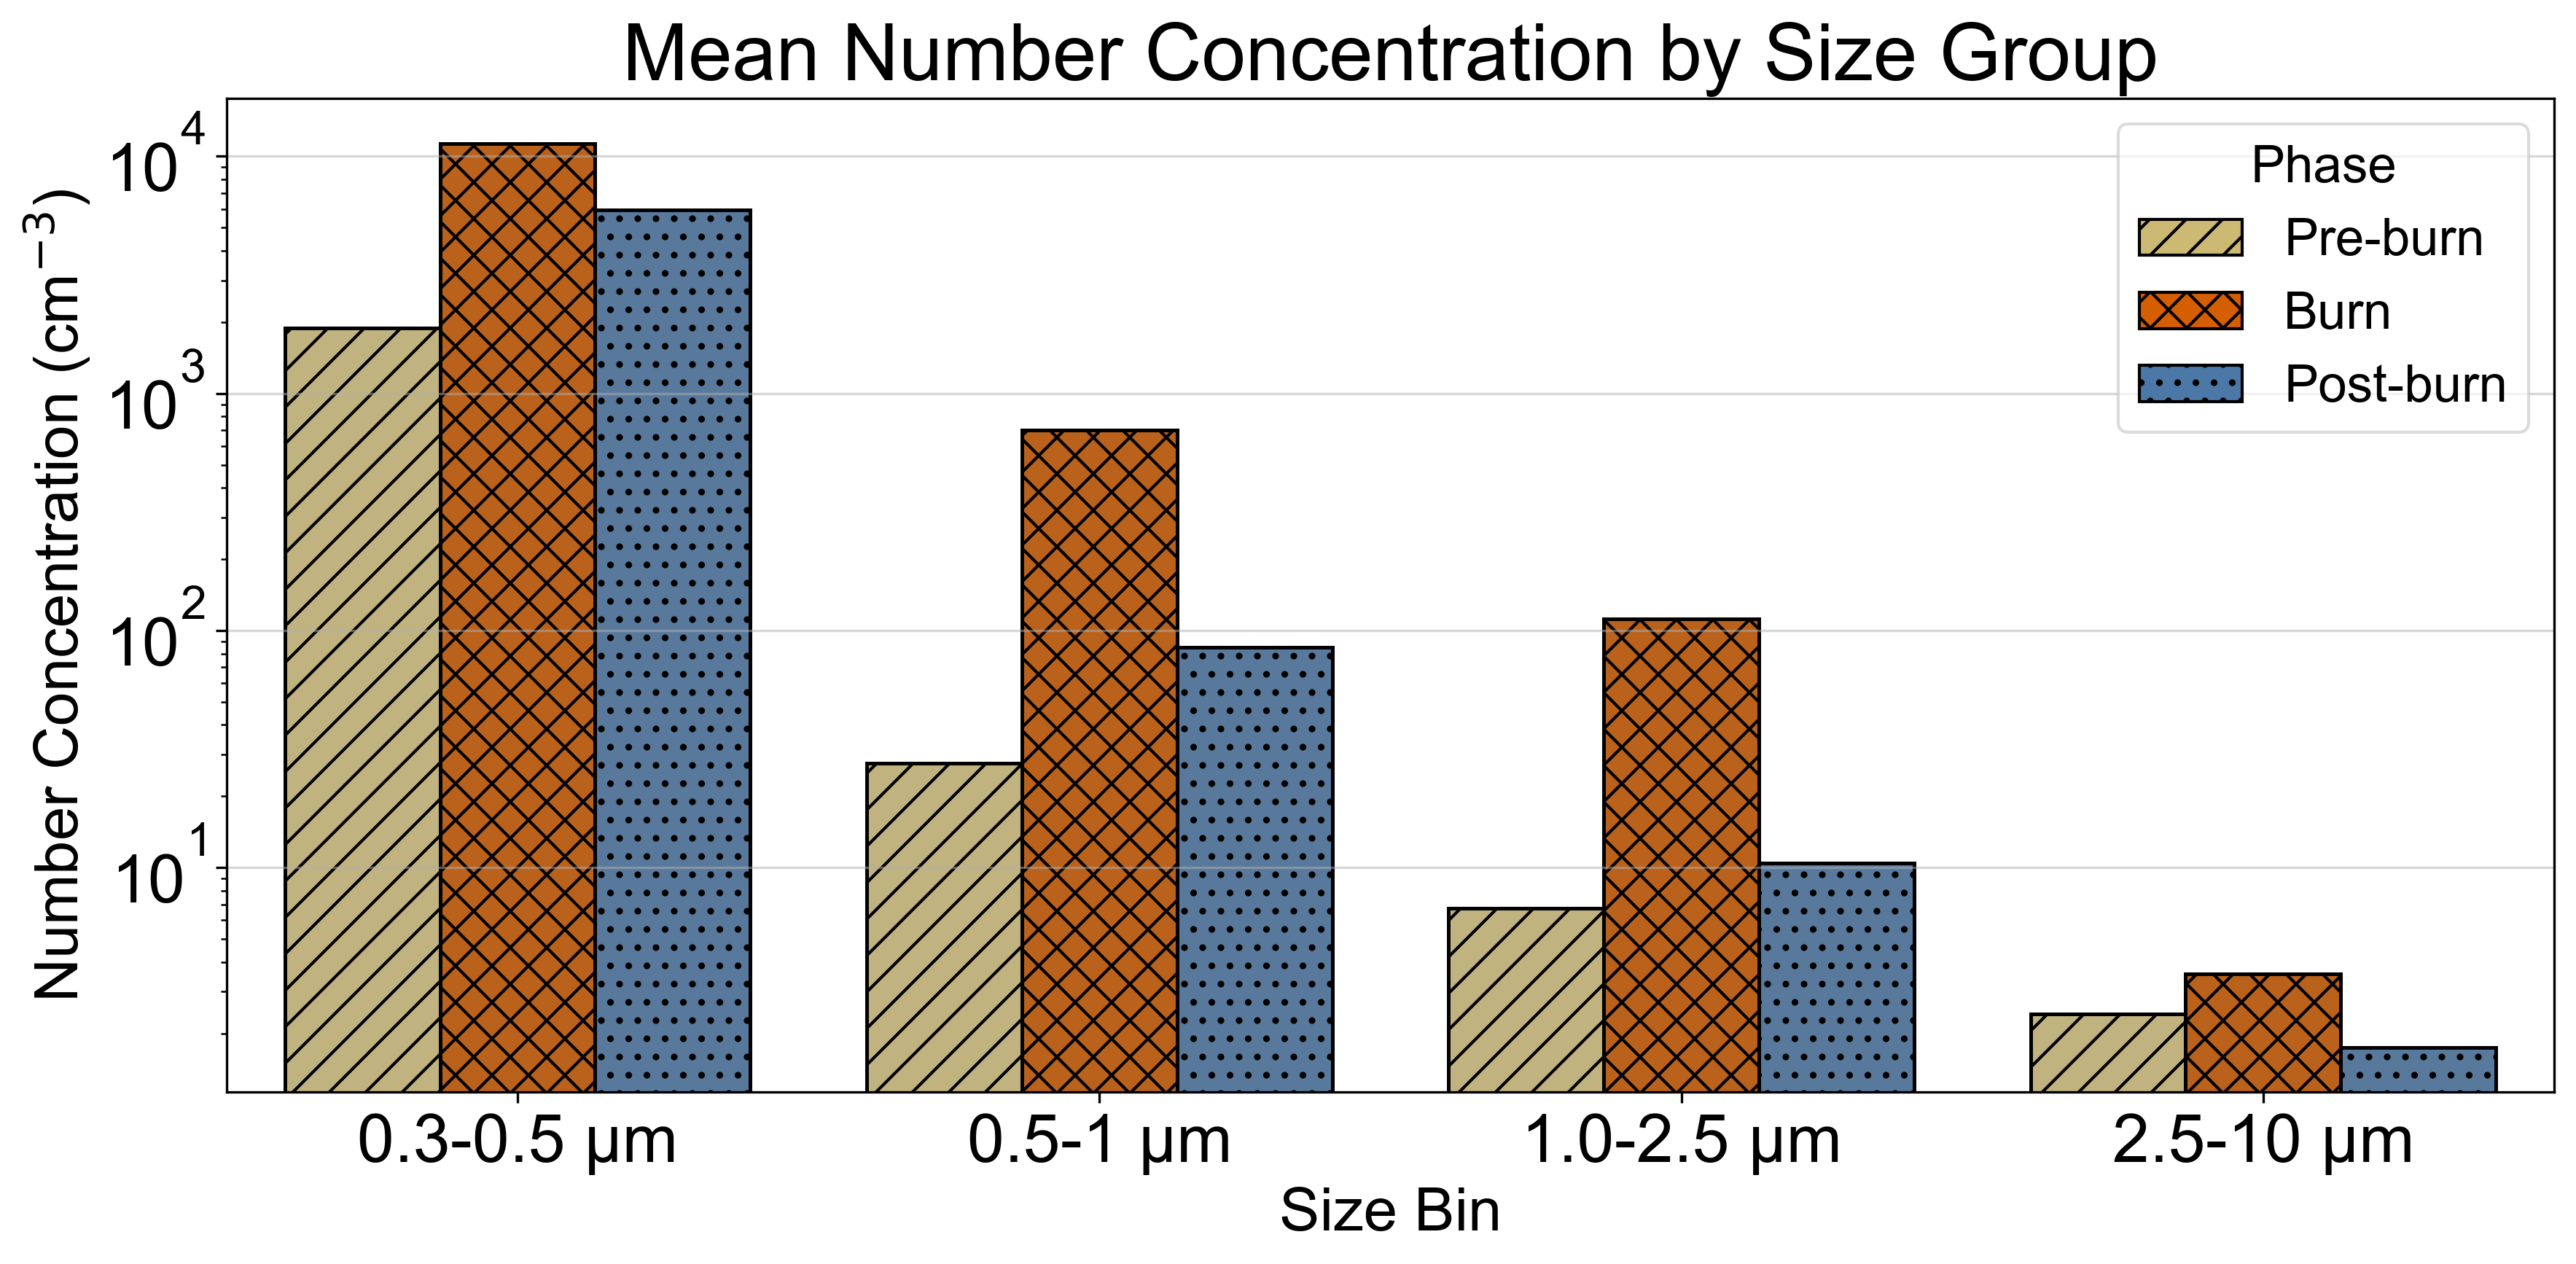

In [185]:
bin_cols = ['0.3-0.5 µm', '0.5-1 µm', '1.0-2.5 µm', '2.5-10 µm']
phase_order = ['Pre-burn', 'Burn', 'Post-burn']

# make sure Phase is ordered
ops_df['Phase'] = pd.Categorical(ops_df['Phase'], categories=phase_order, ordered=True)

# mean concentration by phase
means = ops_df.groupby('Phase')[bin_cols].mean().reset_index()

# reshape for plotting
means_long = means.melt(
    id_vars='Phase',
    value_vars=bin_cols,
    var_name='Size Bin',
    value_name='Mean Concentration'
)

# optional: keep bins in the order you want
means_long['Size Bin'] = pd.Categorical(
    means_long['Size Bin'],
    categories=bin_cols,
    ordered=True
)

palette = {
    "Pre-burn": "#CCB974",
    "Burn": "#D55E00",
    "Post-burn": "#4C78A8"
}

hatch_map = {
    "Pre-burn": "//",
    "Burn": "xx",
    "Post-burn": ".."
}

fig, ax = plt.subplots(figsize=(12, 6))

sns.barplot(
    data=means_long,
    x='Size Bin',
    y='Mean Concentration',
    hue='Phase',
    hue_order=phase_order,
    palette=palette,
    edgecolor='black',
    linewidth=1.2,
    ax=ax
)

# apply hatches by phase container
for container, phase in zip(ax.containers, phase_order):
    for bar in container:
        bar.set_hatch(hatch_map[phase])

# custom legend so hatches appear
legend_handles = [
    Patch(facecolor=palette[phase], edgecolor='black', hatch=hatch_map[phase], label=phase)
    for phase in phase_order
]
ax.legend(handles=legend_handles, title='Phase', title_fontsize=17, fontsize=17, loc='upper right', framealpha=0.7)

ax.set_xlabel('Size Bin')
ax.set_ylabel('Number Concentration (cm$^{-3}$)')
ax.set_title('Mean Number Concentration by Size Group')
ax.set_yscale('log')   # optional
# plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

3


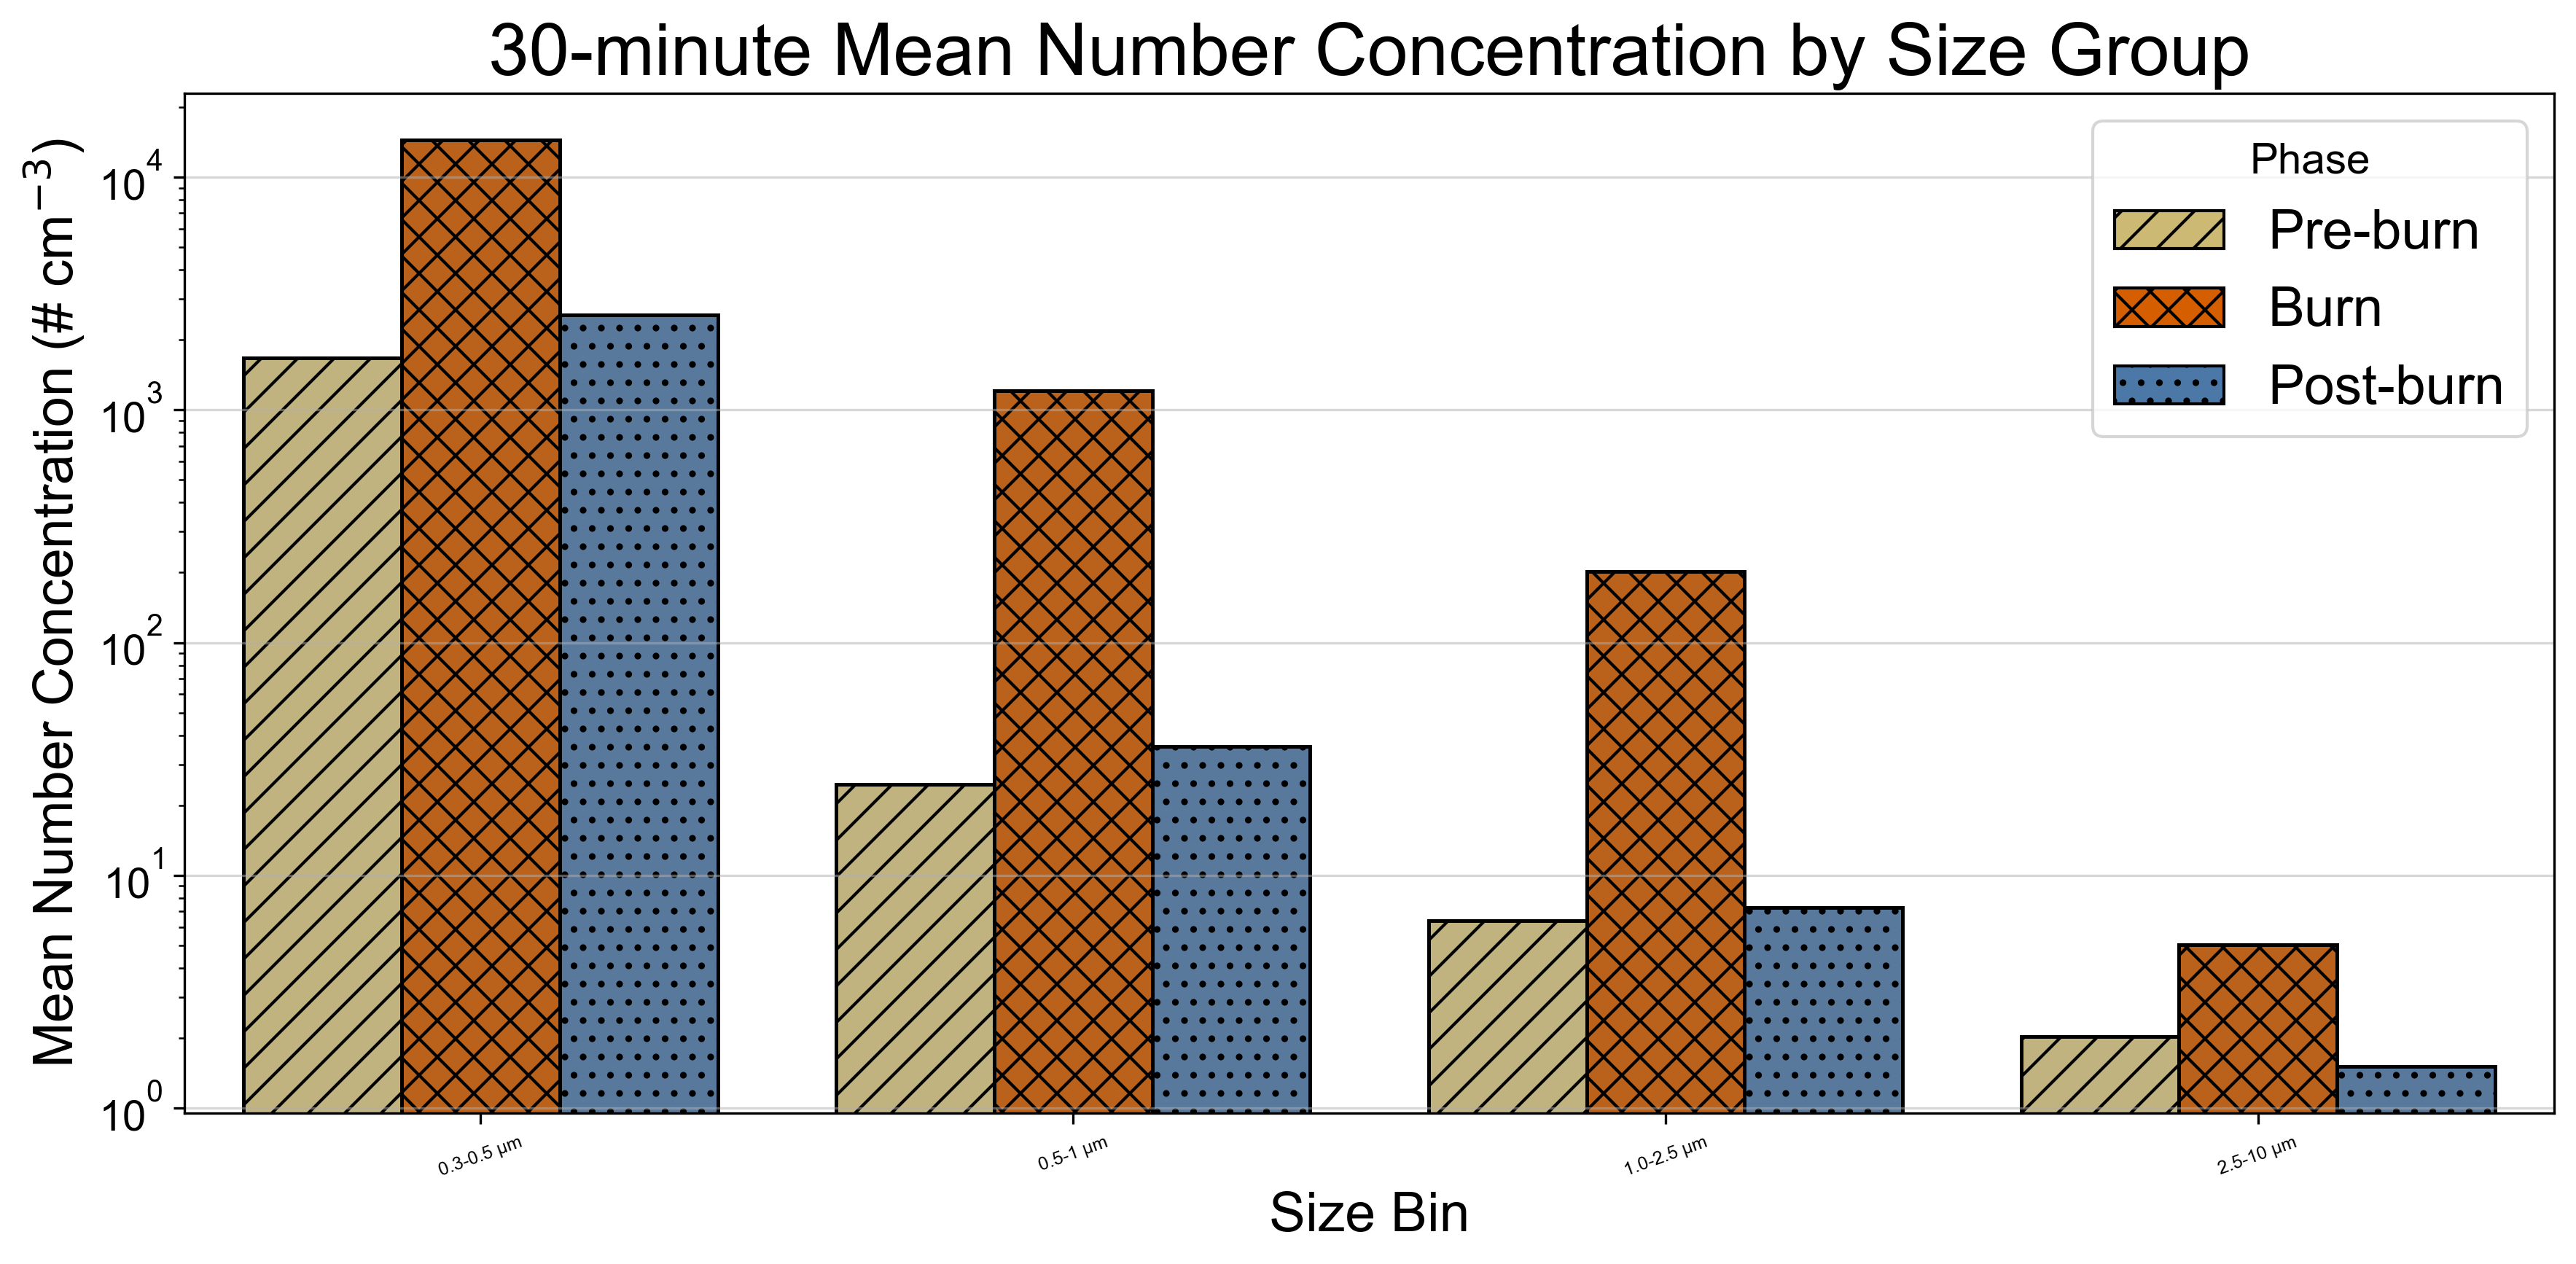

In [99]:
# Origninally I used three 30-minute windows for pre-burn, burn, and post-burn; found here. 

bin_cols = ['0.3-0.5 µm', '0.5-1 µm', '1.0-2.5 µm', '2.5-10 µm']
phase_order = ['Pre-burn', 'Burn', 'Post-burn']

# Define windows of interest
pre_start, pre_end   = "2025-06-10 08:30", "2025-06-10 09:00"
burn_start, burn_end = "2025-06-10 09:45", "2025-06-10 10:15"
post_start, post_end = "2025-06-10 12:30", "2025-06-10 13:00"

pre = ops_df.loc[pre_start:pre_end]
burn = ops_df.loc[burn_start:burn_end]
post = ops_df.loc[post_start: post_end]

pre["Phase"]  = "Pre-burn"
burn["Phase"] = "Burn"
post["Phase"] = "Post-burn"

plot_ops_df = pd.concat([pre, burn, post])

# make sure Phase is ordered
plot_ops_df['Phase'] = pd.Categorical(plot_ops_df['Phase'], categories=phase_order, ordered=True)

# mean concentration by phase
means = plot_ops_df.groupby('Phase')[bin_cols].mean().reset_index()

print(len(means))
# reshape for plotting
means_long = means.melt(
    id_vars='Phase',
    value_vars=bin_cols,
    var_name='Size Bin',
    value_name='Mean Concentration'
)

# optional: keep bins in the order you want
means_long['Size Bin'] = pd.Categorical(
    means_long['Size Bin'],
    categories=bin_cols,
    ordered=True
)

palette = {
    "Pre-burn": "#CCB974",
    "Burn": "#D55E00",
    "Post-burn": "#4C78A8"
}

hatch_map = {
    "Pre-burn": "//",
    "Burn": "xx",
    "Post-burn": ".."
}

fig, ax = plt.subplots(figsize=(12, 6))

sns.barplot(
    data=means_long,
    x='Size Bin',
    y='Mean Concentration',
    hue='Phase',
    hue_order=phase_order,
    palette=palette,
    edgecolor='black',
    linewidth=1.2,
    ax=ax
)

# apply hatches by phase container
for container, phase in zip(ax.containers, phase_order):
    for bar in container:
        bar.set_hatch(hatch_map[phase])

# custom legend so hatches appear
legend_handles = [
    Patch(facecolor=palette[phase], edgecolor='black', hatch=hatch_map[phase], label=phase)
    for phase in phase_order
]
ax.legend(handles=legend_handles, title='Phase')

ax.set_xlabel('Size Bin')
ax.set_ylabel('Mean Number Concentration (# cm$^{-3}$)')
ax.set_title('30-minute Mean Number Concentration by Size Group')
ax.set_yscale('log')   # optional
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## DustTrak II


In [100]:
def read_dusttrak(csv_file_path):
    """ Reads the DustTrak data from a CSV file and returns a DataFrame with metadata.
    Returns (Tuple):
        metadata_dict (dict): Dictionary containing metadata from the DustTrak file.
        df (pd.DataFrame): DataFrame containing the DustTrak data.
    """
    # read the csv file
    with open(csv_file_path, 'r') as f:
        content = f.readlines()

    metadata = content[0:19]  # first 6 lines are metadata
    # convert metadata to a dictionary
    metadata_dict = {}
    for line in metadata:
        try:
            key, value = line.split(',')
            metadata_dict[key.strip()] = value.strip()
        except ValueError:
            pass

    df = pd.read_csv(csv_file_path, skiprows=19) 
    # convert columns to appropriate data types
    start_datetime = dt.datetime.strptime(
            f"{metadata_dict['Test Start Date']} {metadata_dict['Test Start Time']}"
            , "%m/%d/%Y %I:%M:%S %p"
        )
    df['datetime'] = start_datetime + pd.to_timedelta(df['Elapsed Time [s]'], unit='s')
    
    # reoder columns to have datetime first
    cols = df.columns.tolist()
    cols = cols[-1:] + cols[:-1]
    df = df[cols]

    return [metadata_dict, df]


In [101]:
dt_file = r"..\data\00_raw\DT\BURN TRIAL_003.csv"

dt = read_dusttrak(dt_file)

# trim first 10 minutes of day 2 and day 3 data
dt[1] = dt[1][dt[1]['datetime'] >= dt[1]['datetime'].min() + pd.Timedelta(minutes=10)]

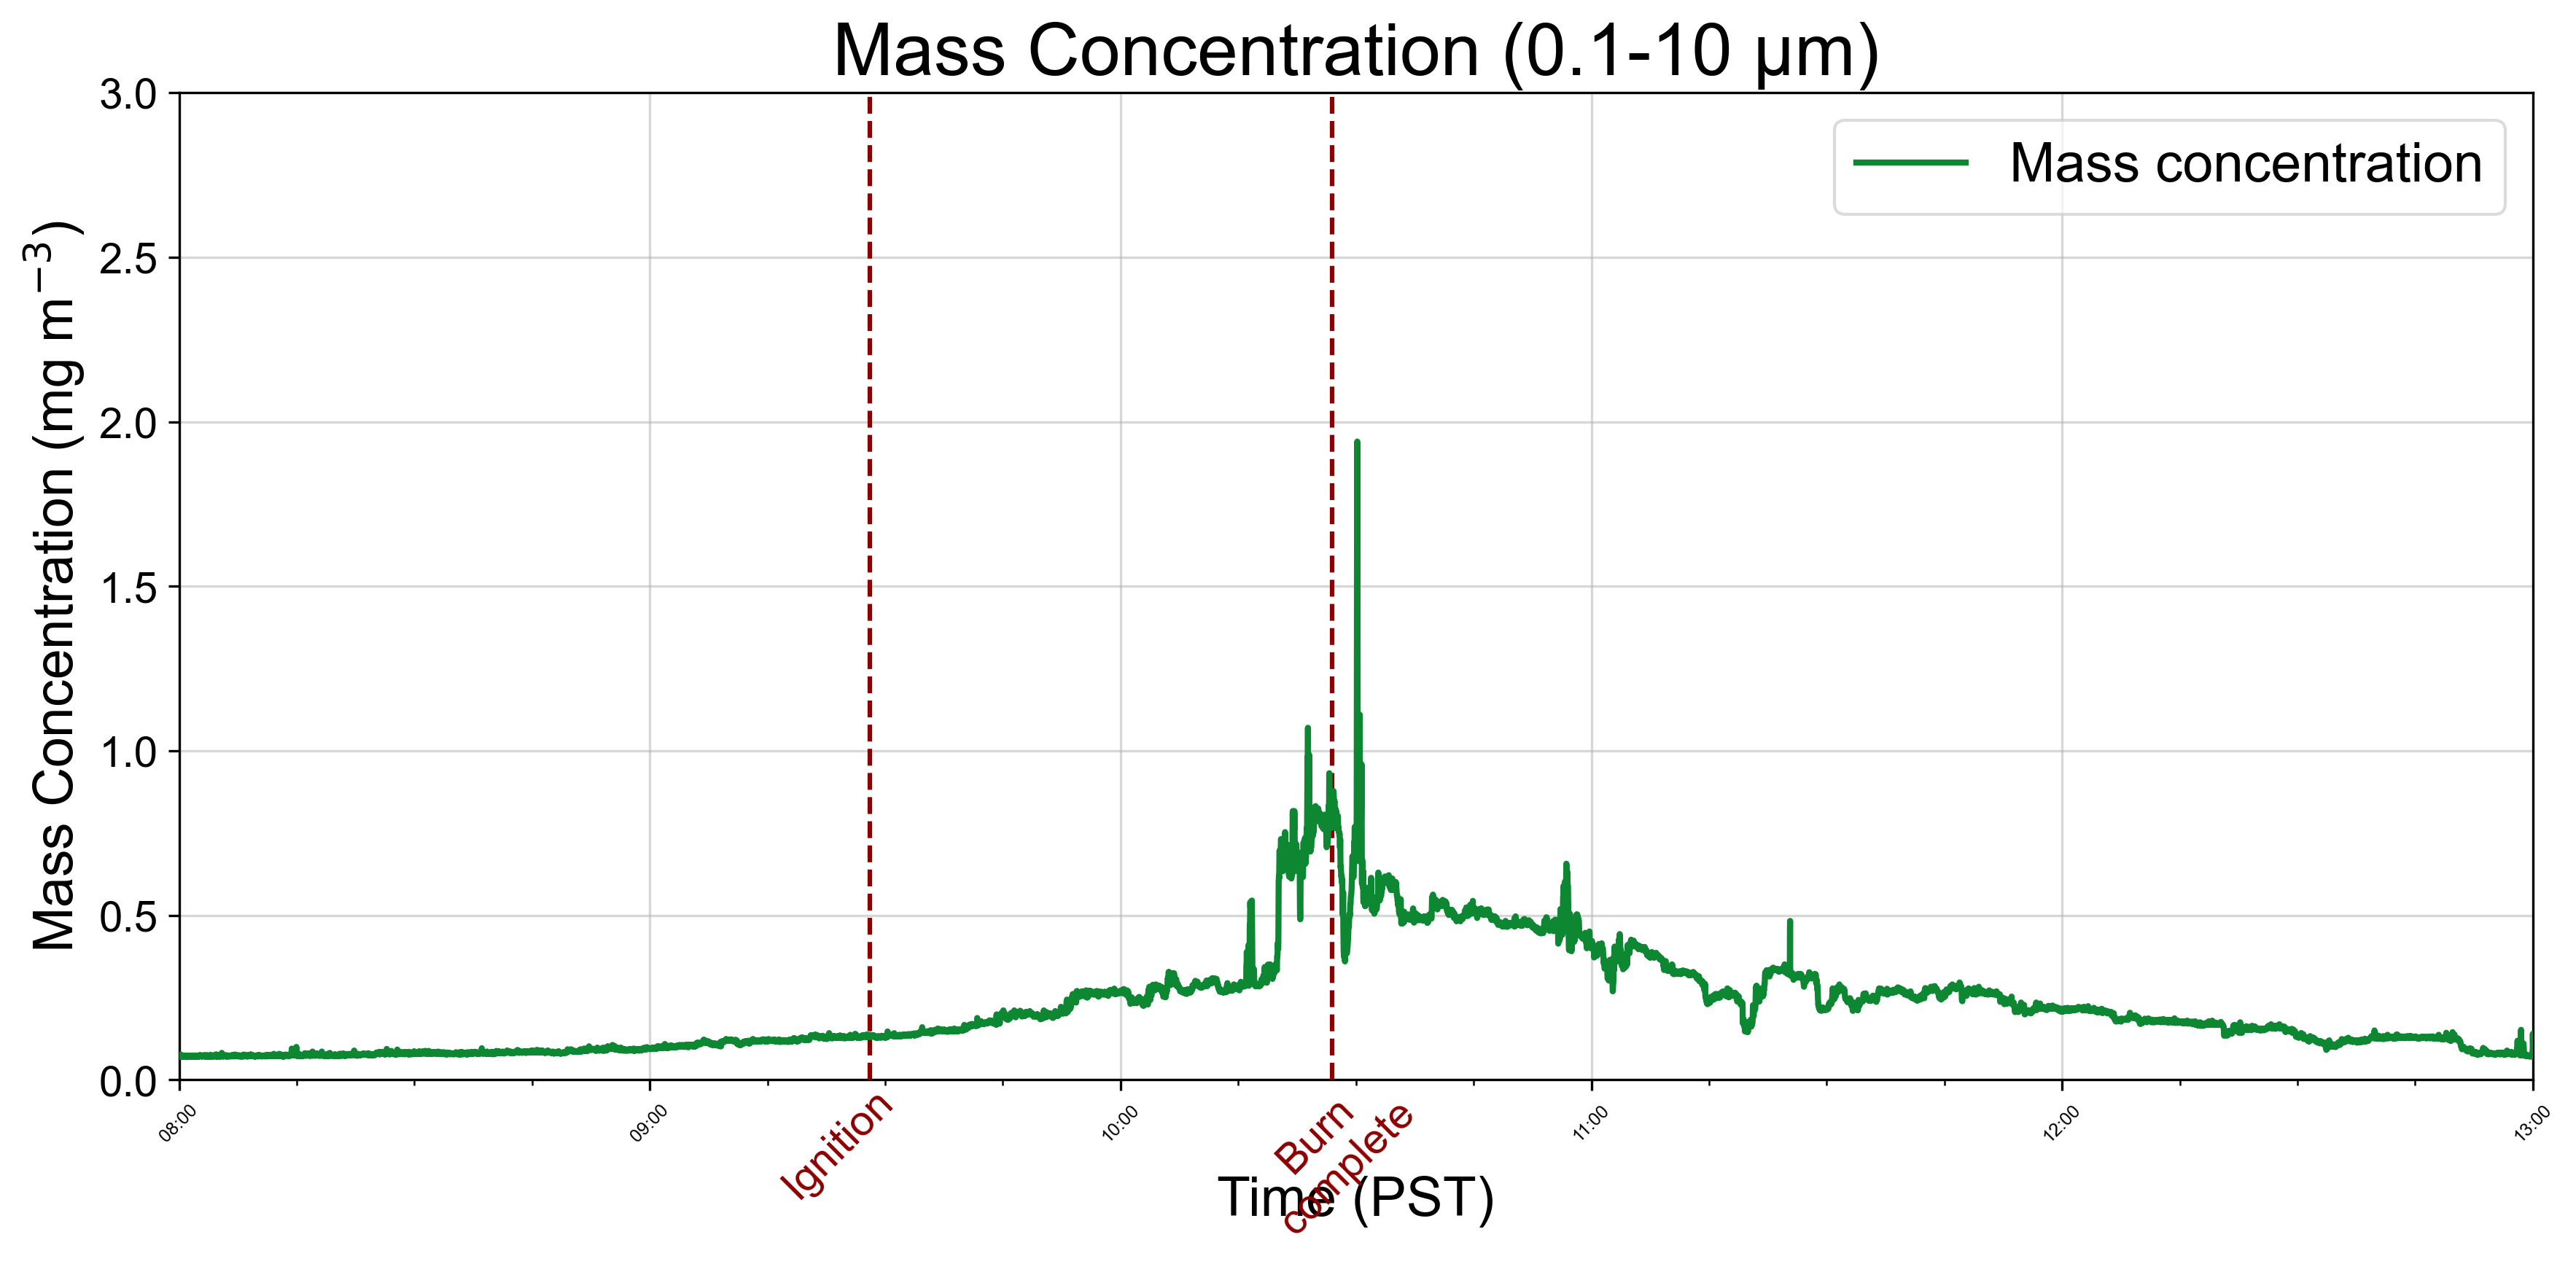

In [102]:
# Plotting DustTrak data with event lines

plt.figure(figsize=(12, 6))

# plt.plot(ops_df.index, ops_df['PM1_smooth'], color='#0072B2',linestyle='-', linewidth=2)
plt.plot(dt[1]['datetime'], dt[1]['Mass [mg/m3]'], label='Mass concentration', color="#0D8732", linewidth=2, zorder=100)

# italics for size range in title
plt.title('Mass Concentration (0.1-10 µm)')
plt.xlabel('Time (PST)', labelpad=10)
plt.ylabel('Mass Concentration (mg m$^{-3}$)')

# format x-axis
time_formatter = mdates.DateFormatter("%H:%M")
plt.gca().xaxis.set_major_formatter(time_formatter)
plt.gca().xaxis.set_minor_locator(mdates.MinuteLocator(byminute=[0, 15, 30, 45]))
plt.xticks(rotation=45)
plt.xlim(pd.Timestamp('2025-06-10 08:00:00'), pd.Timestamp('2025-06-10 13:00:00'))
ax = plt.gca()

plt.axvline(x=ignition, color='darkred', linestyle='--', linewidth=1.5, zorder=10)
plt.axvline(x=burn_complete, color='darkred', linestyle='--', linewidth=1.5, zorder=10)

ax.text(
    ignition- pd.Timedelta(minutes=4), -0.001, 'Ignition',
    transform=ax.get_xaxis_transform(),
    rotation=45, va='top', ha='center',
    color='darkred', clip_on=False
)

ax.text(
    burn_complete, 0.02, 'Burn\ncomplete',
    transform=ax.get_xaxis_transform(),
    rotation=45, va='top', ha='center',
    color='darkred', clip_on=False
)


plt.legend(framealpha=0.7)

# plt.yscale('log') # don't need log scale here. 
plt.ylim(0, 3.0)
plt.show()


## Saving data for others

In [103]:
ops_columns_drop = ['Elapsed Time [s]', 'Temperature (C)', 'Humidity (%)', 
       'Ambient Pressure (kPa)', 'Alarms', 'Unnamed: 24', 'PM1', 'PM2.5', 
       'PM10', 'PM1_smooth', 'PM25_smooth', 'PM10_smooth', '0.3-0.5 µm', 
       '0.5-1 µm', '1.0-2.5 µm', '2.5-10 µm']
ops_df_final = ops_df.drop(columns=ops_columns_drop)
ops_df_final.columns

Index(['Bin 1', 'Bin 2', 'Bin 3', 'Bin 4', 'Bin 5', 'Bin 6', 'Bin 7', 'Bin 8',
       'Bin 9', 'Bin 10', 'Bin 11', 'Bin 12', 'Bin 13', 'Bin 14', 'Bin 15',
       'Bin 16', 'Bin 17', 'Deadtime (s)', 'Errors', 'Phase'],
      dtype='str')

In [104]:
ops_df_final

,Bin 1,Bin 2,Bin 3,Bin 4,Bin 5,Bin 6,Bin 7,Bin 8,Bin 9,Bin 10,Bin 11,Bin 12,Bin 13,Bin 14,Bin 15,Bin 16,Bin 17,Deadtime (s),Errors,Phase
datetime,,,,,,,,,,,,,,,,,,,,
2025-06-10 08:05:54,781,203,25,4,5,5,2,2,0,0,0,2,0,0,0,0,0,0.005753,NaN,Pre-burn
2025-06-10 08:05:55,731,211,34,10,2,6,1,1,1,1,3,0,1,0,0,0,0,0.005766,NaN,Pre-burn
2025-06-10 08:05:56,797,183,39,7,7,6,1,1,3,0,0,0,0,0,0,0,0,0.005662,NaN,Pre-burn
2025-06-10 08:05:57,791,214,32,12,2,3,4,0,2,0,0,0,0,0,0,0,0,0.005999,NaN,Pre-burn
2025-06-10 08:05:58,781,206,35,5,3,1,0,2,3,0,0,0,0,0,0,0,0,0.005752,NaN,Pre-burn
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-06-10 13:39:20,270,89,18,8,1,3,3,3,1,0,0,0,0,0,0,0,0,0.002126,NaN,Post-burn
2025-06-10 13:39:21,316,89,13,7,6,5,2,3,1,2,0,0,1,0,0,0,0,0.002478,NaN,Post-burn
2025-06-10 13:39:22,280,93,16,7,5,4,0,4,1,1,1,1,0,0,1,0,0,0.002285,NaN,Post-burn


In [105]:
ops_df_final.to_csv(r"..\data\02_processed\ops\ops_2025_06_10.csv")

In [106]:
ops_meta

{'Instrument Name': 'Optical Particle Sizer',
 'Model Number': '3330',
 'Serial Number': '3330142801',
 'Firmware Version': '1.4',
 'Calibration Date': '2018/07/03',
 'Protocol Name_Number': 'TEST_001',
 'Test Start Time': '07:55:53',
 'Test Start Date': '2025/06/10',
 'Test Length [D:H:M:S]': '0:5:43:31',
 'Sample Interval [H:M:S]': '0:0:1',
 'Number Channels Enabled': '16',
 'Alarm': '0.000 #/cm3',
 'Density': '1.000',
 'Refractive Index': '0.000-0.000j',
 'Size Correction Factor': '0.000',
 'FlowCal': '1.000',
 'DeadTime Correction Factor': '1.000',
 'Errors': 'Coincidence Error',
 'Number of Samples': '20611',
 '': '',
 'Bin Cut Points': {1: 0.3,
  2: 0.374,
  3: 0.465,
  4: 0.579,
  5: 0.721,
  6: 0.897,
  7: 1.117,
  8: 1.391,
  9: 1.732,
  10: 2.156,
  11: 2.685,
  12: 3.343,
  13: 4.162,
  14: 5.182,
  15: 6.451,
  16: 8.031,
  17: 10.0}}

In [107]:
dt[1].to_csv(r"..\data\02_processed\dt\dt_2025_06_10.csv", index=False)

In [108]:
dt[0]

{'Instrument Name': 'DustTrak II',
 'Model Number': '8530',
 'Serial Number': '8530183103',
 'Firmware Version': '3.7',
 'Calibration Date': '08/02/2018',
 'Test Name': 'BURN TRIAL_003',
 'Test Start Time': '07:39:07 AM',
 'Test Start Date': '06/10/2025',
 'Test Length [D:H:M]': '0:6:30',
 'Test Interval [M:S]': '0:1',
 'Mass Average [mg/m3]': '0.188',
 'Mass Minimum [mg/m3]': '0.046',
 'Mass Maximum [mg/m3]': '2.88',
 'Mass TWA [mg/m3]': '0.153',
 'Photometric User Cal': '1.00',
 'Flow User Cal': '0.00',
 'Errors': '',
 'Number of Samples': '23411'}